# 03 — Complete epoch-wise training analysis

Every genuine per-epoch record in the repository, in one long-format table, with the eight required plots. Nothing is interpolated.

**Evidence base**

- `full_doc_report/tables/REMEDFILM_EPOCH_HISTORY.csv` (35,764 records)
- `full_doc_report/tables/TRAINING_RUN_REGISTRY.csv` (82 runs)
- `experiments/*/history.csv` (82 source logs)

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 3.1 The long-format table

In [3]:
hist = pd.read_csv(TABLES / "REMEDFILM_EPOCH_HISTORY.csv")
print("records:", len(hist), "| runs:", hist.run_id.nunique(),
      "| metrics:", hist.metric.nunique())
hist.head(8)

records: 35764 | runs: 82 | metrics: 42


,run_id,model_identity,model_role,seed,epoch,metric,value,source_metric_column,source_path
0,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,train_loss,1.245044e+01,train_loss,experiments/h3_kub_localizer_sigma_adaptive_si...
1,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,val_loss,1.037506e+01,val_loss,experiments/h3_kub_localizer_sigma_adaptive_si...
2,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,learning_rate,9.997533e-05,learning_rate,experiments/h3_kub_localizer_sigma_adaptive_si...
3,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,epoch_seconds,3.292958e+02,epoch_seconds,experiments/h3_kub_localizer_sigma_adaptive_si...
4,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,peak_gpu_allocated,7.555871e+08,peak_gpu_allocated,experiments/h3_kub_localizer_sigma_adaptive_si...
5,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,peak_gpu_reserved,9.059697e+08,peak_gpu_reserved,experiments/h3_kub_localizer_sigma_adaptive_si...
6,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,val_localizer_tiny_recall90,0.000000e+00,val_tiny_recall90,experiments/h3_kub_localizer_sigma_adaptive_si...
7,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),PRECURSOR,42,1,val_localizer_overall_recall90,0.000000e+00,val_overall_recall90,experiments/h3_kub_localizer_sigma_adaptive_si...


In [4]:
print("schema:", list(hist.columns))
print()
print("metric coverage (records):")
print(hist.metric.value_counts().head(20).to_string())

schema: ['run_id', 'model_identity', 'model_role', 'seed', 'epoch', 'metric', 'value', 'source_metric_column', 'source_path']

metric coverage (records):
metric
learning_rate                     5094
epoch_seconds                     4739
train_loss                        2440
train_huber                       1786
val_loss                          1755
val_router_huber                  1571
train_bce                         1482
best_epoch_so_far                 1449
val_safety_bce                     803
peak_gpu_allocated                 640
peak_gpu_reserved                  640
val_localizer_tiny_recall90        626
val_localizer_overall_recall90     626
train_dice_loss                    614
val_refiner_loss                   583
val_macro_dice                     539
val_dice                           519
val_iou                            519
val_precision                      519
val_recall                         519


## 3.2 Figures T1–T4 — loss, Dice, IoU, per-domain

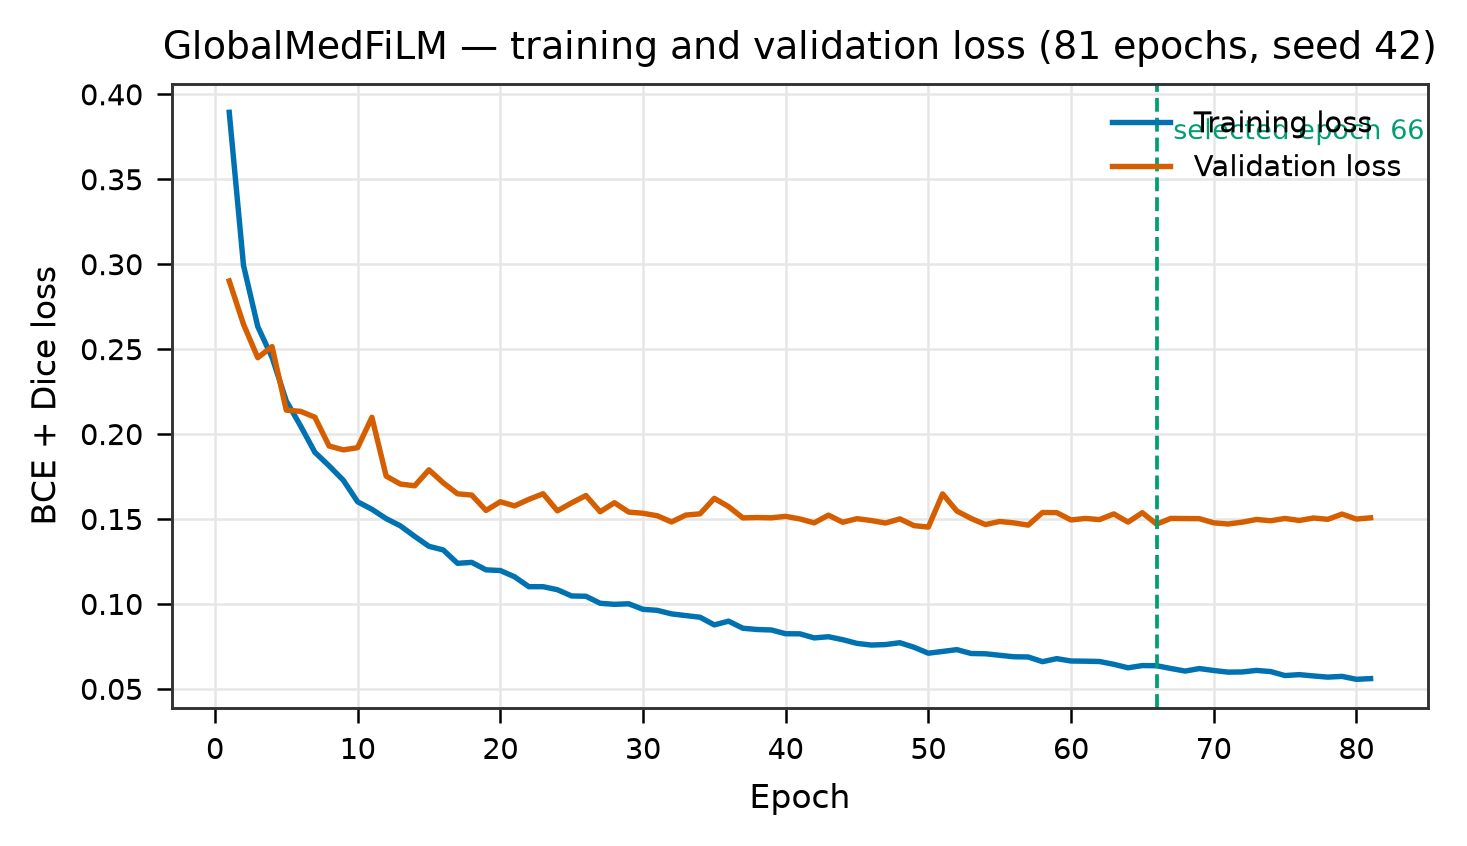

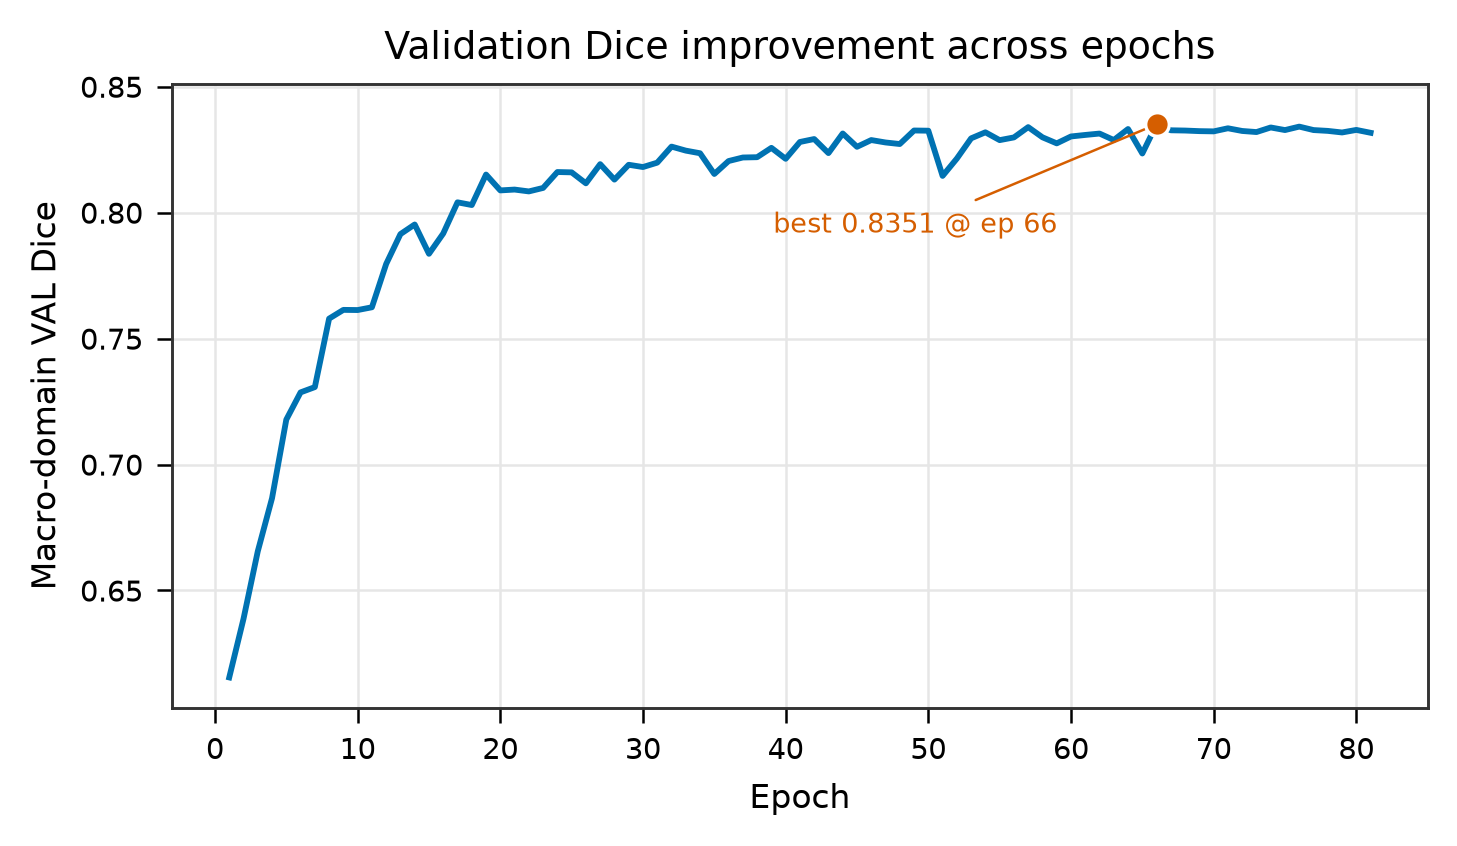

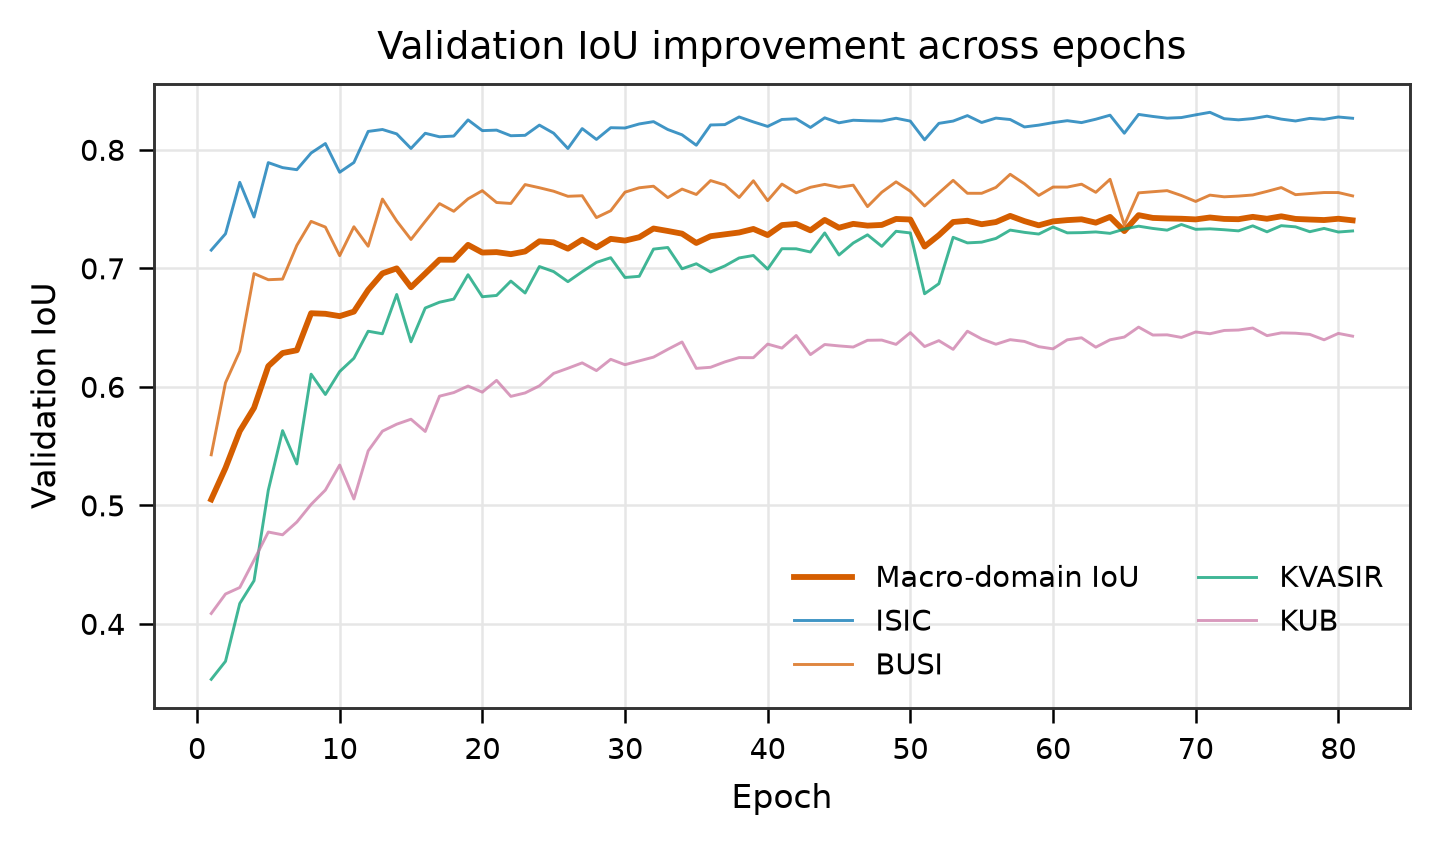

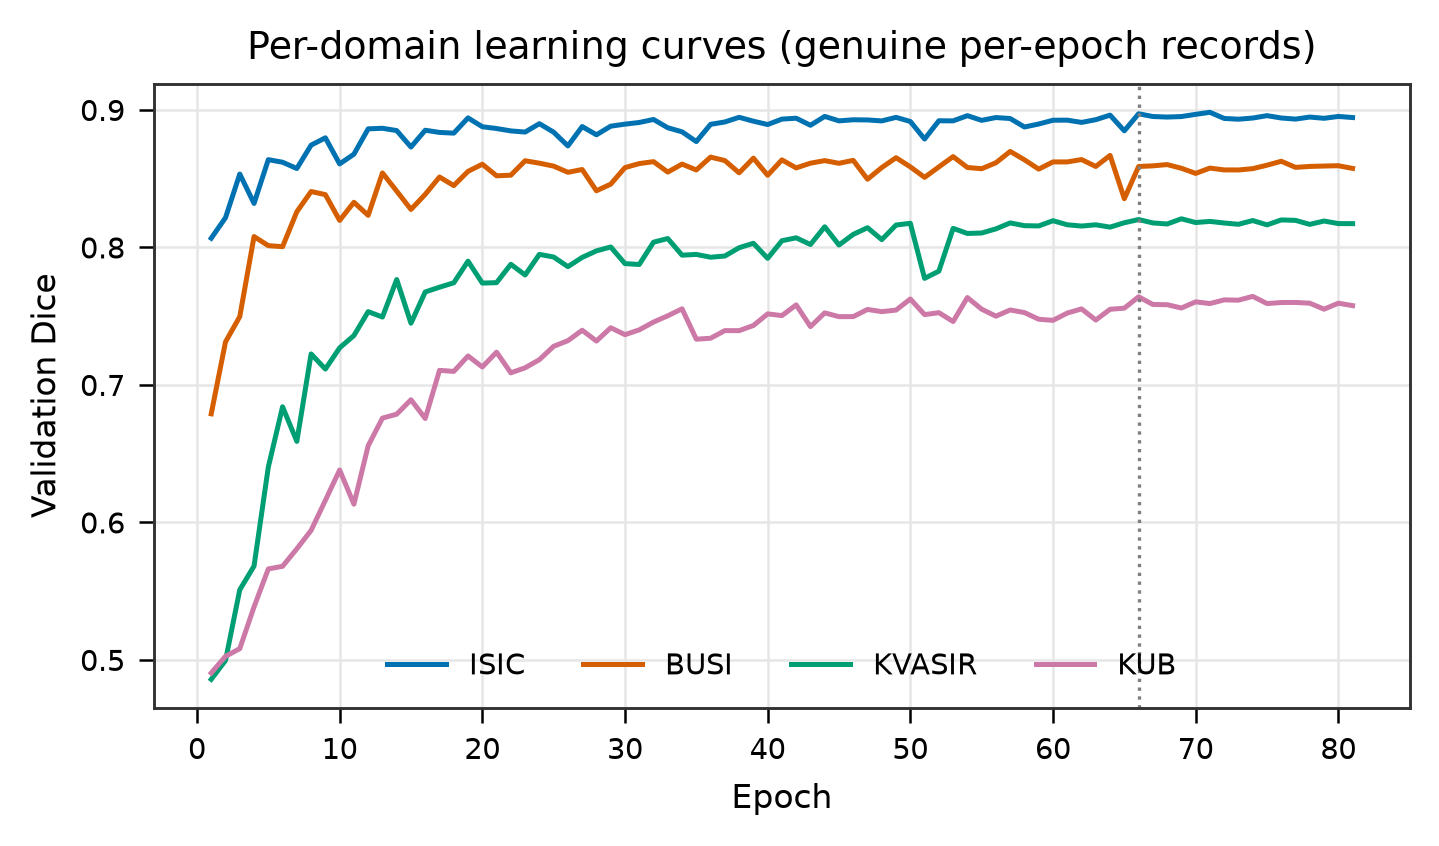

In [5]:
for name, w in [("T1_train_val_loss", 700), ("T2_val_dice_across_epochs", 700),
                ("T3_val_iou_across_epochs", 700), ("T4_per_domain_learning_curves", 700)]:
    fig("Training curves", name, width=w)

## 3.3 Figures T5–T8 — schedule, selection, seeds, summary

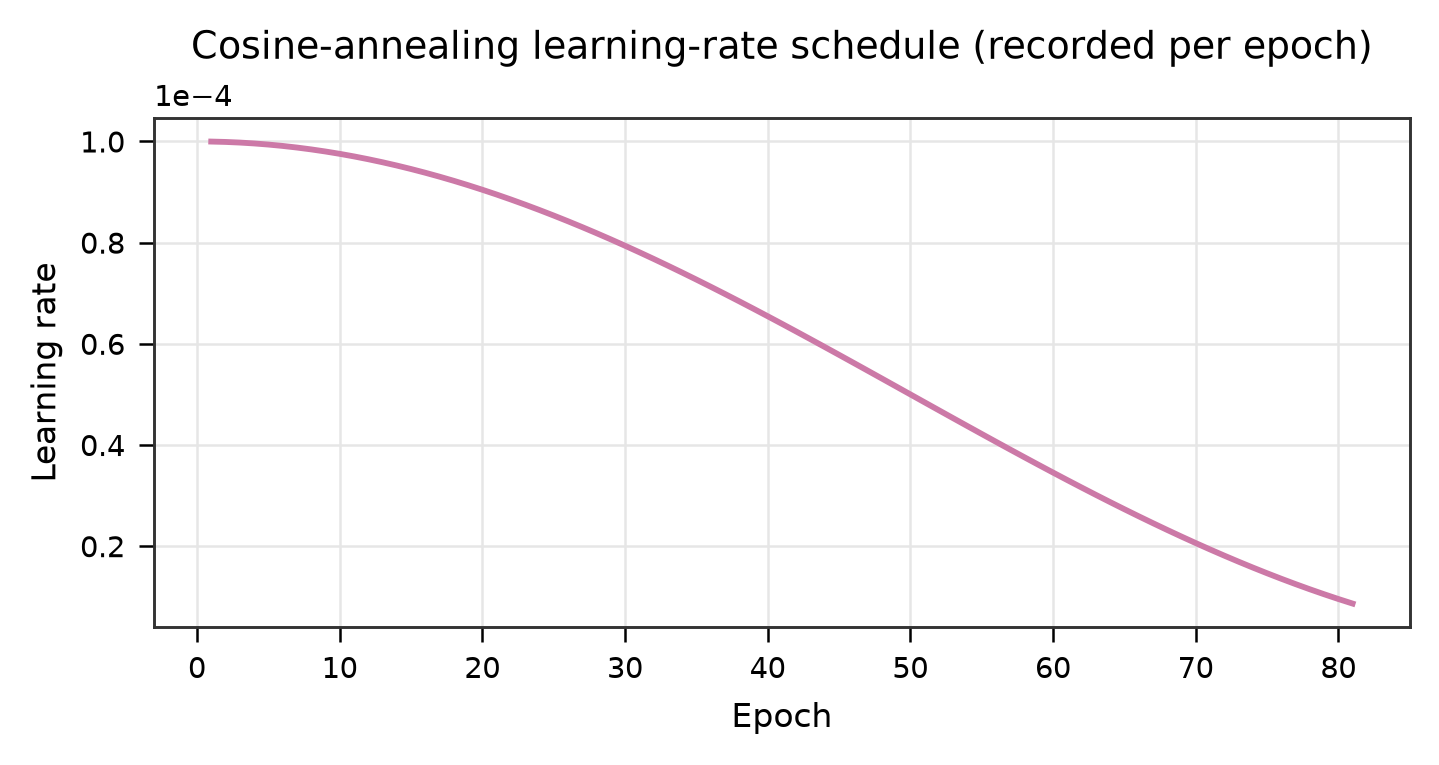

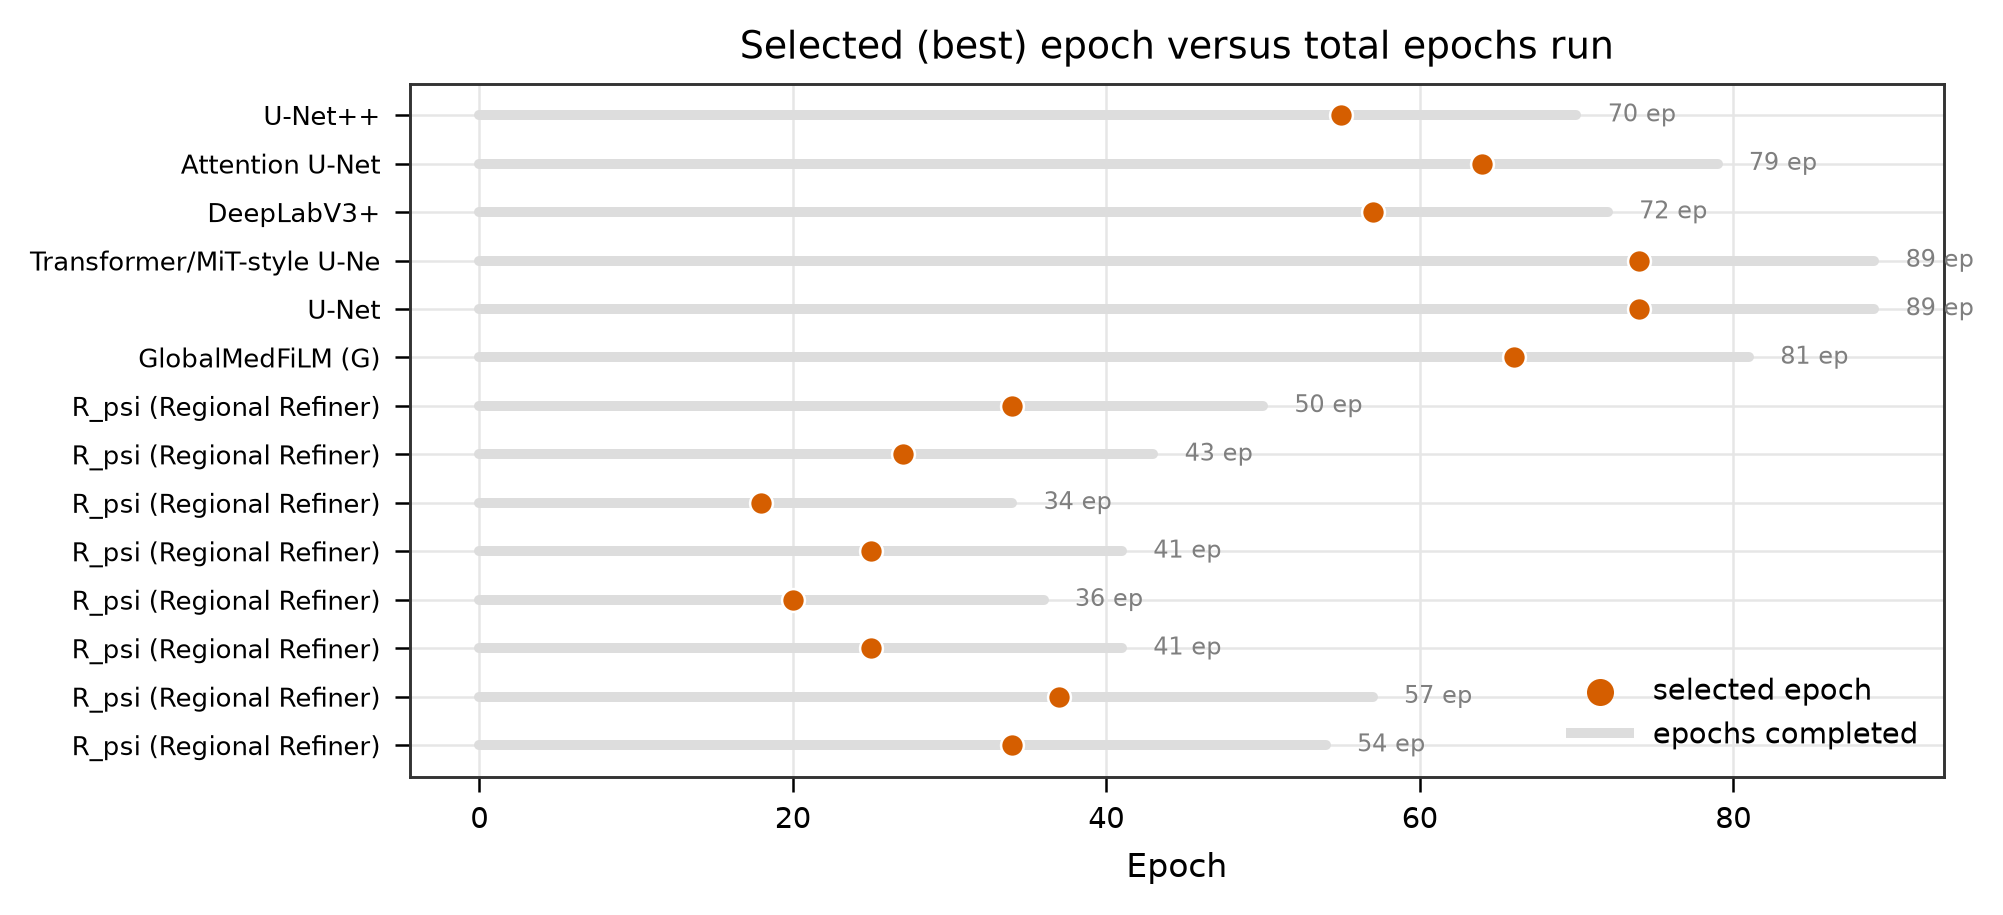

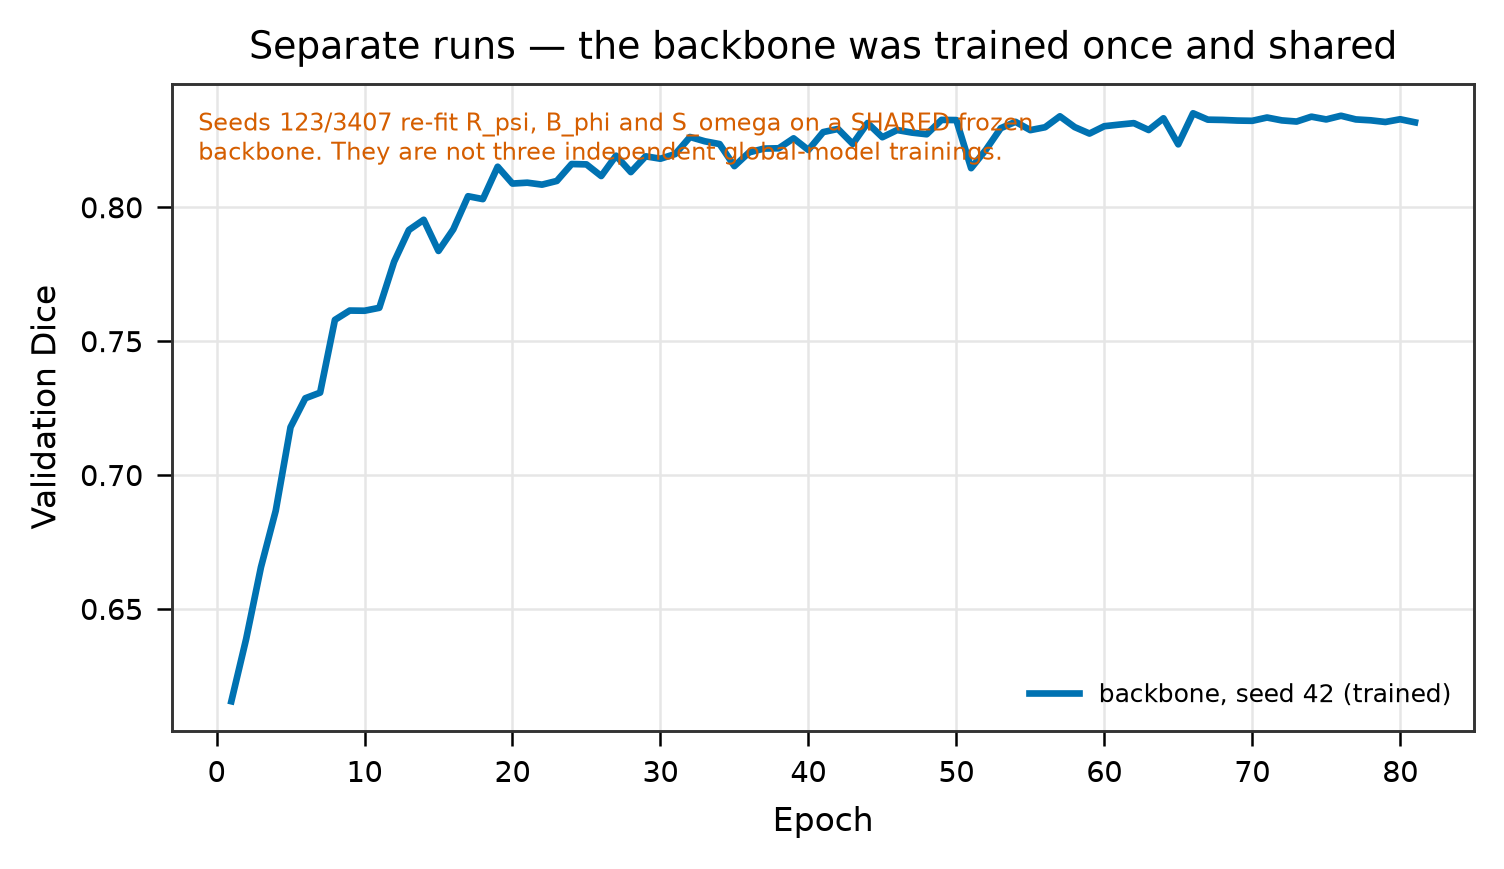

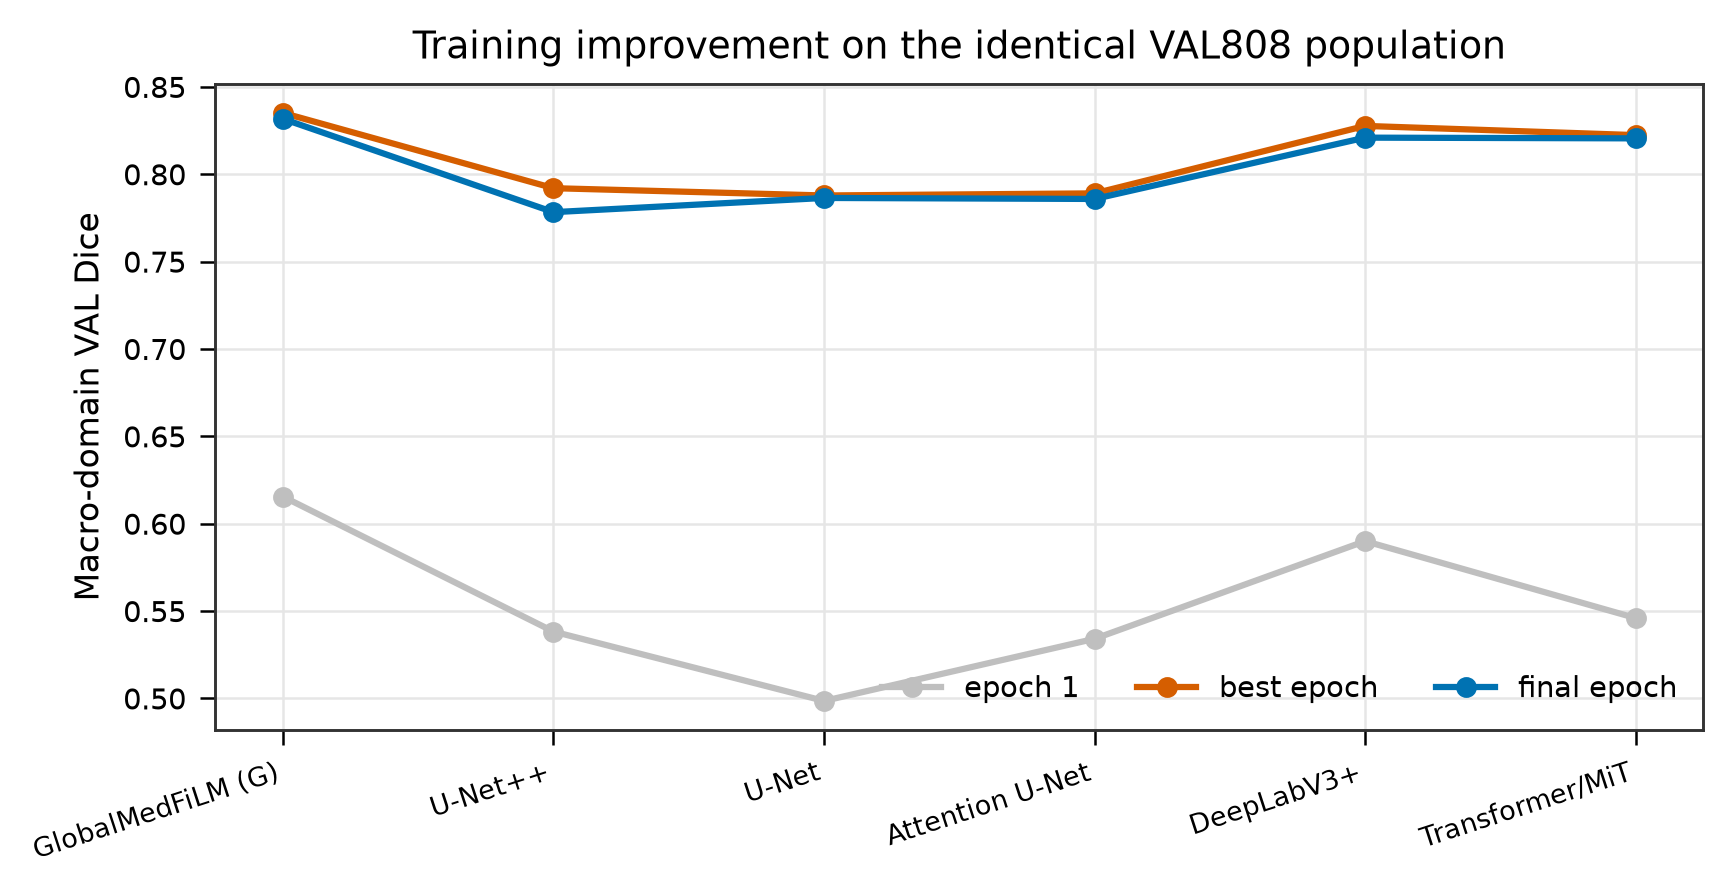

In [6]:
for name in ["T5_learning_rate_schedule", "T6_best_epoch_selection",
             "T7_multiseed_histories", "T8_training_improvement_summary"]:
    fig("Training curves", name, width=700)

## 3.4 Component-wise historical summaries

In [7]:
# Component loss curves that genuinely exist.
comp_runs = {
    "R_psi fold0": "phase25a_barr_regional_refiner_v1_1__fold0",
    "B_phi fold0": "phase25d_barr_benefit_router_v1_2_1_seed42__fold0",
    "S_omega cv_fold0": "phase25f_barr_post_safety_v1_0_seed42__cv_fold0",
}
fig_, axes = plt.subplots(1, 3, figsize=(8.6, 2.5))
for ax, (label, rid) in zip(axes, comp_runs.items()):
    sub = hist[hist.run_id == rid]
    tr = sub[sub.metric.isin(["train_loss", "train_huber", "train_bce"])]
    if tr.empty:
        ax.text(0.5, 0.5, "NOT_RECORDED", ha="center", va="center")
    else:
        m = tr.metric.iloc[0]
        d = tr[tr.metric == m].sort_values("epoch")
        ax.plot(d.epoch, d.value.astype(float), linewidth=1.2, color="#0072B2")
        ax.set_xlabel("Epoch"); ax.set_ylabel(m)
    ax.set_title(label, fontsize=7.5)
plt.tight_layout(); plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_43448\1305659058.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


In [8]:
# Which metrics each component family actually logged.
fam = hist.assign(family=hist.model_identity.str.extract(r"(R_psi|B_phi|S_omega|GlobalMedFiLM)")[0])
piv = fam.dropna(subset=["family"]).pivot_table(
    index="family", columns="metric", values="value", aggfunc="count", fill_value=0)
print("records per (family, metric):")
piv.loc[:, piv.sum() > 0]

records per (family, metric):


metric,best_epoch_so_far,best_metric_so_far,epoch_seconds,learning_rate,train_bce,train_dice_loss,train_huber,train_loss,val_dice_BUSI,val_dice_ISIC,...,val_precision_ISIC,val_precision_KUB,val_precision_KVASIR,val_recall_BUSI,val_recall_ISIC,val_recall_KUB,val_recall_KVASIR,val_refiner_loss,val_router_huber,val_safety_bce
family,,,,,,,,,,,,,,,,,,,,,
B_phi,0,0,1216,1216,0,0,1216,0,0,0,...,0,0,0,0,0,0,0,0,1001,0
GlobalMedFiLM,81,81,81,81,0,0,0,81,81,81,...,81,81,81,81,81,81,81,0,0,0
R_psi,614,0,1184,1184,614,614,570,614,0,0,...,0,0,0,0,0,0,0,512,570,0
S_omega,0,0,868,868,868,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,803


## 3.5 Genuine independent seed trajectories

In [9]:
reg = pd.read_csv(TABLES / "TRAINING_RUN_REGISTRY.csv")
seed_runs = reg[reg.seed.astype(str).isin(["42", "123", "3407"])]
print("runs by seed:")
print(seed_runs.seed.value_counts().to_string())
print()
print("DISCLOSURE")
print("----------")
print("Seeds 123 and 3407 re-fit R_psi / B_phi / S_omega on a SHARED FROZEN")
print("GlobalMedFiLM backbone. There are not three independent end-to-end")
print("trainings, and the three trajectories are never drawn as such.")

runs by seed:
seed
42      47
123     16
3407    16

DISCLOSURE
----------
Seeds 123 and 3407 re-fit R_psi / B_phi / S_omega on a SHARED FROZEN
GlobalMedFiLM backbone. There are not three independent end-to-end
trainings, and the three trajectories are never drawn as such.


## 3.6 Explicit `NOT_RECORDED` register

| Metric | Availability |
|---|---|
| Per-epoch per-domain Dice | **only** GlobalMedFiLM and the four-domain baselines |
| Per-epoch Dice for R_psi | `early_stop_dice` only |
| Per-epoch Dice for B_phi / S_omega | **NOT_RECORDED** (loss only) |
| Peak GPU memory | **NOT_RECORDED** for G; `peak_gpu_allocated` for localisers |
| Epoch duration for G | recorded (`epoch_seconds`, mean 426.6 s) |

In [10]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
